# Product category classification: tuned Stage 1 baselines (GCN, GraphSAGE, GAT, GT)

Retrains the four Stage 1 GNNs on the OGB / degree features with the same model and training setup as the later experiments and compares Adam with AdamW.

**Runs:** 64 grid runs (4 models x 16 settings, seed 0, OGB only), then the selected setting per model and optimiser for
seeds 0-2 under the three feature conditions (the seed-0 OGB-only run is the grid run itself, so 64 more training runs),
plus 24 cold-start evaluations.

**Protocol:** Grid is chosen on validation accuracy only.

In [1]:
# Colab only: mount Drive, move into the repository, install PyG. Does nothing elsewhere.
import os, sys
from pathlib import Path
COLAB_REPO = '/content/drive/MyDrive/CS5284_project'
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    repo = Path(COLAB_REPO)
    if not (repo / 'requirements.txt').is_file():
        hits = [p.parent for depth in ('*', '*/*', '*/*/*') for p in repo.parent.glob(f'{depth}/requirements.txt')]
        raise FileNotFoundError(f'requirements.txt not in {repo}. Candidates found: {hits or "none"}')
    os.chdir(repo / 'notebooks' if (repo / 'notebooks').is_dir() else repo)
    get_ipython().run_line_magic('pip', 'install -q torch_geometric')
print('Working in:', os.getcwd())

Mounted at /content/drive
Working in: /content/drive/MyDrive/CS5284_project/notebooks


# Import packages

In [2]:
from pathlib import Path
import copy, hashlib, itertools, json, random, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import GATConv
from torch_geometric.utils import remove_self_loops, to_undirected
from IPython.display import display

# Optional: torch-sparse is only needed to open the released graph file directly (its adjacency is a
# torch_sparse.SparseTensor). Without it, the graph-loading cell makes and uses a plain-tensor copy.
try:
    import torch_sparse
    HAS_TORCH_SPARSE = True
except Exception:  # Missing, or a wheel built for a different PyTorch (OSError).
    torch_sparse, HAS_TORCH_SPARSE = None, False

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'requirements.txt').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Start Jupyter inside the project repository.')
DATA = ROOT / 'data' / 'TAPE'
sys.path.insert(0, str(ROOT))
from src.models import GCN, SAGE, GraphTransformer
from src.gnn_evaluation import evaluate_predictions, save_evaluation, seed_summary

print('PyTorch:', torch.__version__, '| PyG:', torch_geometric.__version__)
print('torch-sparse:', torch_sparse.__version__ if HAS_TORCH_SPARSE else 'not installed (plain graph file will be used)')

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch: 2.14.1+cu130 | PyG: 2.8.1
torch-sparse: not installed (plain graph file will be used)


# Settings

Grids and fixed settings (see the table in the header). `RETRAIN` takes `(architecture, optimiser, condition, seed)`
tuples and retrains every saved run that matches.

In [3]:
SEEDS = [0, 1, 2]
TUNE_SEED = 0                # The grid is run on this seed only.
TUNE_CONDITION = '1_ogb'     # ... and on the OGB-only features.
CONDITIONS = ['1_ogb', '2_ogb_degree', '3_degree']
COLD_CONDITION = '4_ogb_cold'
CLASSES = 47
HIDDEN_DIM = 256
NUM_LAYERS = 2
HEADS = 8                    # GT and the first GAT layer.
GAT_ATTENTION_DROPOUT = 0.2
MAX_EPOCHS = 500
PATIENCE = 50
CPU_THREADS = 4

ARCHITECTURES = ['GCN', 'GraphSAGE', 'GAT', 'GT']
OPTIMISERS = ['Adam', 'AdamW']
LR_GRID = {'GCN': [1e-3, 1e-2], 'GraphSAGE': [1e-3, 1e-2], 'GAT': [1e-3, 1e-2], 'GT': [1e-3, 5e-3]}
DROPOUT_GRID = [0.2, 0.5]
WEIGHT_DECAY_GRID = {'Adam': [5e-4], 'AdamW': [0.01, 0.1, 0.5]}

RESUME = True
RETRAIN = []  # e.g. [('GT', 'AdamW', '1_ogb', 0)]
REVISION = 'tuned_baselines_v1'  # Stored in every run config; saved runs from another revision are not reused.

RESULTS_DIR = ROOT / 'results' / '1_gnn_ogb' / '03_tuned_baselines'
WEIGHTS_DIR = ROOT / 'outputs' / 'weights' / 'GNN_experiments' / '03_tuned_baselines'
torch.set_num_threads(CPU_THREADS)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, f'({torch.cuda.get_device_name(0)})' if DEVICE.type == 'cuda' else '')
print('Results:', RESULTS_DIR)


def grid_configs(architecture, optimiser):
    """Grid order: lr, then dropout, then weight decay. Ties in validation accuracy keep the earlier setting."""
    return [dict(lr=lr, dropout=dropout, weight_decay=wd)
            for lr in LR_GRID[architecture] for dropout in DROPOUT_GRID for wd in WEIGHT_DECAY_GRID[optimiser]]


print('Grid runs:', sum(len(grid_configs(a, o)) for a in ARCHITECTURES for o in OPTIMISERS))

Device: cuda (Tesla T4)
Results: /content/drive/MyDrive/CS5284_project/results/GNN_experiments/03_tuned_baselines
Grid runs: 64


# Load and validate the data

Check the files, load the graph and validate features, labels and the released masks.

In [4]:
# Check the data files (assumed to be in data/TAPE already); nothing is downloaded.
import hashlib
required = ['ogbn-products_subset.pt', 'ogbn-products_subset.csv', 'labelidx2productcategory.csv.gz']
missing = [name for name in required if not (DATA / name).is_file()]
if missing:
    raise FileNotFoundError(f'Missing from {DATA}: {missing}')

# torch.load unpickles arbitrary objects, so confirm the graph is TAPE's pinned release before loading it.
GRAPH_SHA256 = '70bc85fcbc20c65637729abda51f996bb46fdbfc98145d07ec3855a2ba1779e4'
if hashlib.sha256((DATA / 'ogbn-products_subset.pt').read_bytes()).hexdigest() != GRAPH_SHA256:
    raise ValueError('ogbn-products_subset.pt differs from the TAPE release (commit d9881f7).')

# The graph-loading cell checks the .pt against this manifest; write it if absent.
download_manifest = DATA / 'download_manifest.json'
if not download_manifest.is_file():
    download_manifest.write_text(json.dumps([{'artifact': 'graph', 'sha256': GRAPH_SHA256}], indent=2) + '\n')
for name in required:
    print(f'{name}: OK ({(DATA / name).stat().st_size:,} bytes)')

ogbn-products_subset.pt: OK (25,507,847 bytes)
ogbn-products_subset.csv: OK (37,554,824 bytes)
labelidx2productcategory.csv.gz: OK (628 bytes)


In [5]:
# 1. Define the cached graph and product-text file paths
paths = {'graph': DATA / 'ogbn-products_subset.pt',
         'text': DATA / 'ogbn-products_subset.csv',
         'mapping': DATA / 'labelidx2productcategory.csv.gz'
         }

# 2. Load the graph
# With torch-sparse: the released file. Without it (e.g. Colab with a PyTorch too new for PyG's
# torch-sparse wheels): a plain-tensor copy. The copy is made once, here, by unpickling the released file with
# every torch_geometric / torch_sparse class replaced by an empty placeholder; the tensors inside are ordinary PyTorch tensors. Later runs load the copy directly.
if HAS_TORCH_SPARSE:
    graph = torch.load(paths['graph'], map_location='cpu', weights_only=False)
    GRAPH_SOURCE = paths['graph'].name
else:
    import hashlib, pickle, types

    plain_path = DATA / 'ogbn-products_subset_plain.pt'
    plain_manifest = DATA / 'ogbn-products_subset_plain.json'
    PLAIN_KEYS = {'num_nodes', 'x', 'y', 'train_mask', 'val_mask', 'test_mask', 'n_id', 'edge_index'}

    def sha256(path):
        return hashlib.sha256(path.read_bytes()).hexdigest()

    plain_ok = (plain_path.is_file() and plain_manifest.is_file() and
                json.loads(plain_manifest.read_text()).get('plain_sha256') == sha256(plain_path))
    if not plain_ok:
        print('torch-sparse is not installed: making a plain-tensor copy of the graph (one time only).')
        # torch.load unpickles arbitrary objects, so check the released file against its download manifest.
        source_sha = sha256(paths['graph'])
        download_manifest = DATA / 'download_manifest.json'
        if download_manifest.is_file():
            expected = next((item['sha256'] for item in json.loads(download_manifest.read_text())
                             if item.get('artifact') == 'graph'), None)
            if expected is not None and expected != source_sha:
                raise ValueError(f"{paths['graph'].name} does not match download_manifest.json; re-download it.")
        else:
            print('Warning: data/TAPE/download_manifest.json not found; the graph file was not checked.')

        class _Placeholder:
            # Stands in for any torch_geometric / torch_sparse class while unpickling.
            def __init__(self, *args, **kwargs):
                self._args = args
            def __setstate__(self, state):
                parts = state if isinstance(state, tuple) else (state,)
                for part in parts:
                    if isinstance(part, dict):
                        self.__dict__.update(part)

        class _PlaceholderUnpickler(pickle.Unpickler):
            def find_class(self, module, name):
                if module.split('.')[0] in ('torch_geometric', 'torch_sparse', 'torch_scatter'):
                    return _Placeholder
                return super().find_class(module, name)

        _placeholder_pickle = types.ModuleType('placeholder_pickle')
        _placeholder_pickle.__dict__.update(pickle.__dict__)
        _placeholder_pickle.Unpickler = _PlaceholderUnpickler

        def _fields(obj):
            # All named attributes of a PyG Data object (newer PyG keeps them in _store._mapping).
            items = obj if isinstance(obj, dict) else dict(vars(obj))
            out = {}
            for key, value in items.items():
                if key in ('_store', '_mapping') and not torch.is_tensor(value):
                    out.update(_fields(value))
                else:
                    out[key] = value
            return out

        raw = torch.load(paths['graph'], map_location='cpu', weights_only=False, pickle_module=_placeholder_pickle)
        store = _fields(raw)
        storage = vars(vars(store['adj_t'])['storage'])  # torch_sparse.SparseTensor -> SparseStorage
        row, col, rowptr = storage.get('_row'), storage.get('_col'), storage.get('_rowptr')
        if row is None:  # Only the compressed row pointer was stored.
            row = torch.repeat_interleave(torch.arange(rowptr.numel() - 1), rowptr[1:] - rowptr[:-1])
        n_raw = int(store['x'].shape[0])
        payload = {
            'num_nodes': n_raw,
            'x': store['x'].float().contiguous(),
            'y': store['y'].reshape(-1).long().contiguous(),
            'train_mask': store['train_mask'].bool().reshape(-1).contiguous(),
            'val_mask': store['val_mask'].bool().reshape(-1).contiguous(),
            'test_mask': store['test_mask'].bool().reshape(-1).contiguous(),
            'n_id': store['n_id'].long().contiguous(),
            # adj_t is transposed: rows are destinations, columns are sources.
            'edge_index': torch.stack([col, row]).long().contiguous(),
        }
        assert all(payload[k].shape[0] == n_raw for k in ['y', 'train_mask', 'val_mask', 'test_mask', 'n_id'])
        assert row.numel() == col.numel() and int(payload['edge_index'].max()) < n_raw
        torch.save(payload, plain_path)
        plain_manifest.write_text(json.dumps({
            'source': paths['graph'].name, 'source_sha256': source_sha, 'plain': plain_path.name,
            'plain_sha256': sha256(plain_path), 'num_nodes': n_raw,
            'stored_edges': int(payload['edge_index'].shape[1]),
            'edge_index': 'stack([col, row]) of adj_t: row 0 = source, row 1 = destination',
            'code': 'Stage 1 Graph Transformer notebook, graph-loading cell (placeholder unpickler)'}, indent=2) + '\n')
        del raw, store, storage, payload
        print('Saved', plain_path.name, 'and', plain_manifest.name)

    plain_info = json.loads(plain_manifest.read_text())
    payload = torch.load(plain_path, map_location='cpu', weights_only=True)  # Plain tensors only.
    if set(payload) != PLAIN_KEYS:
        raise ValueError(f'{plain_path.name} has keys {sorted(payload)}; delete it and its .json and rerun this cell.')
    graph = Data(x=payload['x'], y=payload['y'], edge_index=payload['edge_index'],
                 train_mask=payload['train_mask'], val_mask=payload['val_mask'], test_mask=payload['test_mask'],
                 n_id=payload['n_id'], num_nodes=payload['num_nodes'])
    assert graph.edge_index.shape[1] == plain_info['stored_edges']
    GRAPH_SOURCE = plain_path.name
    print('Stored edges:', plain_info['stored_edges'], '(expected: 74420)')
print('Graph source:', GRAPH_SOURCE)
print("Graph:")
print(graph)

# 3. Load product text and identify the labels of each node
text = pd.read_csv(paths['text'])
mapping = pd.read_csv(paths['mapping'])
mapping = mapping.rename(columns={'label idx': 'label'})

n = int(graph.num_nodes)
labels = np.asarray(graph.y.detach().cpu().reshape(-1).long())
nodes = text.copy()
nodes.insert(0, 'node_id', np.arange(n))
nodes['label'] = labels
nodes = nodes.merge(mapping, on='label', how='left')

# 4. Identify each node's released train/val/test split
split_by_node = np.full(n, 'unassigned', dtype=object)
assigned = np.zeros(n, dtype=bool)
for split, attr in [('train', 'train_mask'), ('val', 'val_mask'), ('test', 'test_mask')]:
    mask = getattr(graph, attr).detach().cpu()
    if mask.shape == (n, 1):
        mask = mask[:, 0]
    assert mask.dtype == torch.bool and mask.shape == (n,), attr
    mask = mask.numpy()
    assert not (assigned & mask).any(), 'Overlapping splits'
    split_by_node[mask] = split
    assigned |= mask
nodes['split'] = split_by_node[nodes['node_id'].to_numpy()]

print('\nNodes:')
print(f"Distinct product categories in original mapping: {len(mapping)}")
print(f"Distinct product categories in ogbn subset data: {nodes['product category'].nunique()}")
display(nodes)

Stored edges: 74420 (expected: 74420)
Graph source: ogbn-products_subset_plain.pt
Graph:
Data(x=[54025, 100], edge_index=[2, 74420], y=[54025], train_mask=[54025], val_mask=[54025], test_mask=[54025], n_id=[54025], num_nodes=54025)

Nodes:
Distinct product categories in original mapping: 47
Distinct product categories in ogbn subset data: 42


,node_id,uid,nid,title,content,label,product category,split
0,0,B00JXMX35K,1324660,Aimee Gowns Original Bra-less Nursing Gown (X-...,The one that started it all! The nightgown's m...,11,"Clothing, Shoes & Jewelry",test
1,1,B000XQHYFU,1670226,Casio DR-270TM 2-Color Professional Desktop Pr...,Heavy duty printing,18,Office Products,test
2,2,B00B67RO9Q,1780321,NaN,NaN,4,Books,test
3,3,B005JN9CKM,2447868,Muay Thai Shorts-Black,"for Size Chart, please see attached photos. Im...",11,"Clothing, Shoes & Jewelry",test
4,4,B00CU9YBVS,1940019,Smatree&reg; Chest Belt/Strap Harness Mount+ A...,1. Smatree chest strap is fully adjustable to ...,12,Electronics,test
...,...,...,...,...,...,...,...,...
54020,54020,0787965383,2276523,Distributed Leadership,&#8220;We all know how important leadership is...,4,Books,test
54021,54021,049591049X,18428,American Public School Law,"""Kern Alexander was the lead author of this te...",4,Books,train
54022,54022,0470651725,66543,The Leadership Challenge: How to Make Extraord...,NaN,4,Books,train
54023,54023,1930556748,1189359,Data Analysis for Continuous School Improvement,Solve your school's problems by using data.Thi...,4,Books,test


In [6]:
# Extract features and labels; validate shapes, values and category IDs.
n = int(graph.num_nodes)
x = graph.x.detach().cpu().float()
y = graph.y.detach().cpu().reshape(-1).long()
assert len(nodes) == len(y) == n
assert x.ndim == 2 and x.shape[0] == n and x.shape[1] > 0 and torch.isfinite(x).all()
assert ((y >= 0) & (y < CLASSES)).all()

# Released split masks; they must not overlap.
masks = {}
for split, attr in [('train', 'train_mask'), ('valid', 'val_mask'), ('test', 'test_mask')]:
    m = getattr(graph, attr).detach().cpu()
    if m.shape == (n, 1):
        m = m[:, 0]
    assert m.dtype == torch.bool and m.shape == (n,) and m.any(), attr
    masks[split] = m
assert (torch.stack(list(masks.values())).sum(0) <= 1).all(), 'Overlapping splits'
print('Features:', tuple(x.shape), '| labels:', tuple(y.shape))
print({split: int(mask.sum()) for split, mask in masks.items()})

Features: (54025, 100) | labels: (54025,)
{'train': 14708, 'valid': 1572, 'test': 37745}


# Graph preparation

Convert the released adjacency into source-to-destination edges, remove self-loops, symmetrise and deduplicate. No self-loops are added, as in the later experiments, GCNConv, GATConv and the GT add their own, and
GraphSAGE keeps a separate self weight instead. Cold start removes every co-purchase edge that touches a test node, at
inference only.

In [7]:
if getattr(graph, 'adj_t', None) is not None:
    assert tuple(graph.adj_t.sparse_sizes()) == (n, n)
    row, col, _ = graph.adj_t.coo()
    edges = torch.stack([col, row]).long()  # adj_t is transposed: rows are destinations.
else:
    edges = graph.edge_index.detach().cpu().long()  # Plain copy: already [source, destination].
assert edges.ndim == 2 and edges.shape[0] == 2 and ((edges >= 0) & (edges < n)).all()
edges, _ = remove_self_loops(edges)
co_purchase_edges = to_undirected(edges, num_nodes=n)
print('Unique undirected edges without loops:', co_purchase_edges.shape[1] // 2)

# Raw degree: unique co-purchase neighbours, before any self-loop.
node_degree = torch.bincount(co_purchase_edges[1], minlength=n).float().unsqueeze(1)
assert int(node_degree.sum()) == co_purchase_edges.shape[1]
print('Raw degree min / mean / max:', node_degree.min().item(), node_degree.mean().item(), node_degree.max().item())

keep = ~(masks['test'][co_purchase_edges[0]] | masks['test'][co_purchase_edges[1]])
cold_co_purchase_edges = co_purchase_edges[:, keep]
assert not masks['test'][cold_co_purchase_edges].any()
print('Cold-start undirected edges removed:', int((~keep).sum()) // 2)

Unique undirected edges without loops: 72319
Raw degree min / mean / max: 0.0 2.6772420406341553 26.0
Cold-start undirected edges removed: 63833


## Standardisation and feature conditions

Mean and standard deviation are fitted on the released training nodes only. OGB only (100 inputs), OGB + raw degree
(101) and raw degree only (1), as in Stage 1.

In [8]:
ogb_x = graph.x.detach().cpu().float()
assert ogb_x.shape == (n, 100)
mean = ogb_x[masks['train']].mean(0, keepdim=True)
std = ogb_x[masks['train']].std(0, unbiased=False, keepdim=True).clamp_min(1e-6)
ogb_features = (ogb_x - mean) / std

degree_mean = node_degree[masks['train']].mean(0, keepdim=True)
degree_std = node_degree[masks['train']].std(0, unbiased=False, keepdim=True).clamp_min(1e-6)
degree_features = (node_degree - degree_mean) / degree_std
feature_sets = {'1_ogb': ogb_features,
                '2_ogb_degree': torch.cat([ogb_features, degree_features], dim=1),
                '3_degree': degree_features}
assert {k: v.shape[1] for k, v in feature_sets.items()} == {'1_ogb': 100, '2_ogb_degree': 101, '3_degree': 1}
assert all(torch.isfinite(v).all() for v in feature_sets.values())
print({k: tuple(v.shape) for k, v in feature_sets.items()})

{'1_ogb': (54025, 100), '2_ogb_degree': (54025, 101), '3_degree': (54025, 1)}


In [9]:
# Label names and NumPy copies for the metrics; then move the training tensors to DEVICE.
names = dict(zip(mapping['label'], mapping['product category']))
LABEL_NAMES = [names[i] for i in range(CLASSES)]
NUMPY_MASKS = {split: mask.detach().cpu().numpy() for split, mask in masks.items()}
NUMPY_Y = y.detach().cpu().numpy()

feature_sets = {condition: features.to(DEVICE) for condition, features in feature_sets.items()}
edge_sets = {'normal': co_purchase_edges.to(DEVICE), 'cold': cold_co_purchase_edges.to(DEVICE)}
y_device = y.to(DEVICE)
masks_device = {split: mask.to(DEVICE) for split, mask in masks.items()}

# Models

GCN, GraphSAGE and the GT are imported unchanged from `src/models.py`. The GAT is not in `src/`; the class below is an
exact copy of `GAT` in `exp/g-arch/models.py` (with `v2=False`).

In [10]:
class GAT(nn.Module):
    """GAT (Velickovic et al. 2018), copied from exp/g-arch/models.py."""

    def __init__(self, in_dim, hidden, classes, dropout=0.5, heads=8, attn_dropout=0.2):
        super().__init__()
        self.c1 = GATConv(in_dim, hidden // heads, heads=heads, dropout=attn_dropout)
        self.c2 = GATConv(hidden, classes, heads=1, dropout=attn_dropout)
        self.dropout = dropout

    def forward(self, x, ei):
        x = F.dropout(x, self.dropout, self.training)
        h = F.elu(self.c1(x, ei))
        h = F.dropout(h, self.dropout, self.training)
        return self.c2(h, ei)


def make_model(architecture, in_dim, dropout):
    if architecture == 'GCN':
        return GCN(in_dim, HIDDEN_DIM, CLASSES, dropout=dropout)
    if architecture == 'GraphSAGE':
        return SAGE(in_dim, HIDDEN_DIM, CLASSES, dropout=dropout, num_layers=NUM_LAYERS)
    if architecture == 'GAT':
        return GAT(in_dim, HIDDEN_DIM, CLASSES, dropout=dropout, heads=HEADS, attn_dropout=GAT_ATTENTION_DROPOUT)
    if architecture == 'GT':  # No positional encodings, as in scripts/export_probs.py.
        return GraphTransformer(in_dim, HIDDEN_DIM, CLASSES, dropout=dropout, num_layers=NUM_LAYERS, heads=HEADS)
    raise ValueError(architecture)


def make_optimiser(optimiser, parameters, lr, weight_decay):
    if optimiser == 'Adam':  # L2 penalty added to the gradient, as in src/train.py.
        return torch.optim.Adam(parameters, lr=lr, weight_decay=weight_decay)
    if optimiser == 'AdamW':  # Decoupled weight decay.
        return torch.optim.AdamW(parameters, lr=lr, weight_decay=weight_decay)
    raise ValueError(optimiser)


for architecture in ARCHITECTURES:
    model = make_model(architecture, 100, 0.5)
    print(f'{architecture}: {sum(p.numel() for p in model.parameters()):,} parameters on the OGB-only input')
del model

GCN: 37,935 parameters on the OGB-only input
GraphSAGE: 75,567 parameters on the OGB-only input
GAT: 38,541 parameters on the OGB-only input
GT: 1,223,727 parameters on the OGB-only input


# Training, saving and resuming

`train_model` follows `src/train.py: train` step for step (full batch, cross-entropy on the training nodes, best
validation accuracy kept, stop after `PATIENCE` epochs without a strictly better validation accuracy); only the
optimiser is configurable. Every finished run is saved under
`runs/<optimiser>/<architecture>/<setting>/<condition>/seed_<seed>/` with its config, history and metrics; the
checkpoint is written last, so a run counts as finished only when its config, metrics and checkpoint all exist.

In [11]:
def set_seed(seed):
    """Same as src/train.py: set_seed."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def setting_tag(cfg):
    return f"lr{cfg['lr']:g}_do{cfg['dropout']:g}_wd{cfg['weight_decay']:g}"


def run_paths(architecture, optimiser, cfg, condition, seed):
    run_dir = RESULTS_DIR / 'runs' / optimiser / architecture / setting_tag(cfg) / condition / f'seed_{seed}'
    checkpoint = WEIGHTS_DIR / optimiser / architecture / setting_tag(cfg) / f'{condition}_seed{seed}.pt'
    return run_dir, checkpoint


def expected_config(architecture, optimiser, cfg, condition, seed):
    return dict(revision=REVISION, architecture=architecture, optimiser=optimiser, condition=condition, seed=seed,
                lr=cfg['lr'], dropout=cfg['dropout'], weight_decay=cfg['weight_decay'],
                input_dim=int(feature_sets[condition].shape[1]), hidden_dim=HIDDEN_DIM, layers=NUM_LAYERS,
                heads=HEADS if architecture in ('GAT', 'GT') else None,
                gat_attention_dropout=GAT_ATTENTION_DROPOUT if architecture == 'GAT' else None,
                positional_encoding=None, max_epochs=MAX_EPOCHS, patience=PATIENCE,
                selection='best validation accuracy (strict)', lr_schedule='constant',
                edges='undirected co-purchase, no self-loops added', features_standardised_on='train')


def train_model(model, optimiser, features, edges, lr, weight_decay):
    """src/train.py: train with a configurable optimiser; also logs validation loss and train accuracy."""
    opt = make_optimiser(optimiser, model.parameters(), lr, weight_decay)
    train_mask, valid_mask = masks_device['train'], masks_device['valid']
    best_val, best_state, best_epoch, history = -1.0, None, 0, []
    for epoch in range(MAX_EPOCHS):
        model.train()
        opt.zero_grad()
        out = model(features, edges)
        loss = F.cross_entropy(out[train_mask], y_device[train_mask])
        if not torch.isfinite(loss):
            raise RuntimeError('non-finite training loss')
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            scores = model(features, edges)
            pred = scores.argmax(dim=1)
            val_acc = float((pred[valid_mask] == y_device[valid_mask]).float().mean())
            val_loss = float(F.cross_entropy(scores[valid_mask], y_device[valid_mask]))
            train_acc = float((pred[train_mask] == y_device[train_mask]).float().mean())
        history.append(dict(epoch=epoch, train_loss=float(loss), train_accuracy=train_acc,
                            valid_loss=val_loss, valid_accuracy=val_acc))
        if val_acc > best_val:
            best_val, best_epoch = val_acc, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        elif epoch - best_epoch >= PATIENCE:
            break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_val, best_epoch, best_state


def evaluate(model, features, edges, architecture, optimiser, cfg, condition, seed, best_epoch):
    model.eval()
    with torch.no_grad():
        predictions = model(features, edges).argmax(-1).cpu().numpy()
    bundle = evaluate_predictions(NUMPY_Y, predictions, NUMPY_MASKS, LABEL_NAMES, architecture, condition, seed,
                                  best_epoch, int(features.shape[1]))
    for key in ('metrics', 'groups', 'standardised'):
        bundle[key].insert(1, 'optimiser', optimiser)
        bundle[key].insert(2, 'setting', setting_tag(cfg))
    return bundle


def should_retrain(architecture, optimiser, condition, seed):
    return not RESUME or (architecture, optimiser, condition, seed) in RETRAIN


RUNS = {}  # (architecture, optimiser, setting, condition, seed) -> dict(config, metrics)


def train_or_load(architecture, optimiser, cfg, condition, seed):
    key = (architecture, optimiser, setting_tag(cfg), condition, seed)
    if key in RUNS:
        return RUNS[key]
    run_dir, checkpoint = run_paths(architecture, optimiser, cfg, condition, seed)
    config_path, metrics_path = run_dir / 'config.json', run_dir / f'{condition}_metrics.csv'
    expected = expected_config(architecture, optimiser, cfg, condition, seed)
    if not should_retrain(architecture, optimiser, condition, seed) and config_path.is_file() \
            and metrics_path.is_file() and checkpoint.is_file():
        config = json.loads(config_path.read_text())
        stale = {k: (config.get(k), v) for k, v in expected.items() if config.get(k) != v}
        if stale:
            raise RuntimeError(f'{key}: the saved run was made with different settings {stale}. Nothing was retrained '
                               f'or overwritten. To retrain it on purpose, add {key[:2] + key[3:]} to RETRAIN.')
        RUNS[key] = dict(config=config, metrics=pd.read_csv(metrics_path))
        return RUNS[key]

    started = time.perf_counter()
    set_seed(seed)
    features = feature_sets[condition]
    model = make_model(architecture, features.shape[1], cfg['dropout']).to(DEVICE)
    model, history, best_val, best_epoch, best_state = train_model(
        model, optimiser, features, edge_sets['normal'], cfg['lr'], cfg['weight_decay'])
    train_seconds = time.perf_counter() - started
    bundle = evaluate(model, features, edge_sets['normal'], architecture, optimiser, cfg, condition, seed, best_epoch)
    run_dir.mkdir(parents=True, exist_ok=True)
    save_evaluation(bundle, run_dir, condition)
    history.to_csv(run_dir / 'history.csv', index=False)
    test = bundle['metrics'].set_index('split').loc['test']
    config = dict(**expected, best_epoch=int(best_epoch), epochs_run=len(history), best_valid_accuracy=best_val,
                  test_accuracy=float(test['accuracy']), test_macro_f1_present=float(test['macro_f1_present']),
                  parameters=sum(p.numel() for p in model.parameters()), train_seconds=train_seconds,
                  seconds=time.perf_counter() - started, device=str(DEVICE),
                  gpu=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
                  torch_version=torch.__version__, pyg_version=torch_geometric.__version__,
                  threads=torch.get_num_threads(), finished=time.strftime('%Y-%m-%d %H:%M:%S'))
    config['seconds'] = time.perf_counter() - started
    config_path.write_text(json.dumps(config, indent=2), encoding='utf-8')
    checkpoint.parent.mkdir(parents=True, exist_ok=True)
    torch.save(best_state, checkpoint)  # Written last: marks the run as finished.
    RUNS[key] = dict(config=config, metrics=bundle['metrics'])
    print(f"{architecture}/{optimiser} {setting_tag(cfg)} {condition} seed {seed}: best epoch {best_epoch}, "
          f"valid {best_val:.4f}, test {config['test_accuracy']:.4f}, {config['seconds']:.0f} s", flush=True)
    write_runtime_files()
    return RUNS[key]


def stage_of(condition, seed):
    if condition == COLD_CONDITION:
        return 'cold_start_evaluation'
    return 'grid' if (condition == TUNE_CONDITION and seed == TUNE_SEED) else 'final'


def write_runtime_files():
    """Rebuild the runtime files from every finished run saved on disk (this and earlier sessions)."""
    rows = []
    for path in sorted((RESULTS_DIR / 'runs').glob('*/*/*/*/seed_*/*.json')):
        if path.name not in ('config.json', 'cold_source.json'):
            continue
        c = json.loads(path.read_text())
        if c.get('revision') != REVISION:
            continue
        rows.append(dict(stage=stage_of(c['condition'], c['seed']), architecture=c['architecture'],
                         optimiser=c['optimiser'], setting=path.parents[2].name, condition=c['condition'],
                         seed=c['seed'], epochs_run=c.get('epochs_run'), seconds=c['seconds'],
                         device=c.get('device'), finished=c.get('finished')))
    if not rows:
        return None
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    per_run = pd.DataFrame(rows)
    per_run.to_csv(RESULTS_DIR / 'runtime_per_run.csv', index=False)
    per_model = per_run.pivot_table(index='architecture', columns='stage', values='seconds',
                                    aggfunc=['count', 'sum'], fill_value=0)
    per_model.columns = [f'{stage}_{"runs" if agg == "count" else "seconds"}' for agg, stage in per_model.columns]
    per_model['total_seconds'] = per_run.groupby('architecture')['seconds'].sum()
    per_model['total_minutes'] = per_model['total_seconds'] / 60
    per_model = per_model.reindex([a for a in ARCHITECTURES if a in per_model.index]).round(1)
    per_model.to_csv(RESULTS_DIR / 'runtime_per_model.csv')
    return per_model

# 1. Grid search (seed 0, OGB only)

For every model and optimiser, train each grid setting on seed 0 with the OGB-only features and keep the setting with
the best validation accuracy (ties keep the earlier setting in grid order). Test accuracy is listed for reference only.

In [12]:
grid_rows = []
for architecture in ARCHITECTURES:
    for optimiser in OPTIMISERS:
        for cfg in grid_configs(architecture, optimiser):
            config = train_or_load(architecture, optimiser, cfg, TUNE_CONDITION, TUNE_SEED)['config']
            grid_rows.append(dict(architecture=architecture, optimiser=optimiser, setting=setting_tag(cfg), **cfg,
                                  valid_accuracy=config['best_valid_accuracy'], best_epoch=config['best_epoch'],
                                  epochs_run=config['epochs_run'], seconds=config['seconds'],
                                  test_accuracy=config['test_accuracy'],
                                  test_macro_f1_present=config['test_macro_f1_present']))
grid_results = pd.DataFrame(grid_rows)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

selected = {}
for (architecture, optimiser), rows in grid_results.groupby(['architecture', 'optimiser'], sort=False):
    best = rows.loc[rows['valid_accuracy'].idxmax()]  # idxmax keeps the first maximum (grid order).
    selected[(architecture, optimiser)] = dict(lr=float(best['lr']), dropout=float(best['dropout']),
                                               weight_decay=float(best['weight_decay']))
grid_results['selected'] = [selected[(r.architecture, r.optimiser)] == dict(lr=r.lr, dropout=r.dropout,
                                                                            weight_decay=r.weight_decay)
                            for r in grid_results.itertuples()]
grid_results.to_csv(RESULTS_DIR / 'grid_results.csv', index=False)
selected_configs = pd.DataFrame([dict(architecture=a, optimiser=o, setting=setting_tag(c), **c)
                                 for (a, o), c in selected.items()])
selected_configs.to_csv(RESULTS_DIR / 'selected_configs.csv', index=False)
with pd.option_context('display.max_rows', 100, 'display.width', 200):
    display(grid_results.round(4))
display(selected_configs)

,architecture,optimiser,setting,lr,dropout,weight_decay,valid_accuracy,best_epoch,epochs_run,seconds,test_accuracy,test_macro_f1_present,selected
0,GCN,Adam,lr0.001_do0.2_wd0.0005,0.001,0.2,0.0005,0.8467,498,500,18.9419,0.6970,0.3025,False
1,GCN,Adam,lr0.001_do0.5_wd0.0005,0.001,0.5,0.0005,0.8321,429,480,15.6008,0.6800,0.2922,False
2,GCN,Adam,lr0.01_do0.2_wd0.0005,0.010,0.2,0.0005,0.8613,167,218,7.3239,0.7092,0.3195,True
3,GCN,Adam,lr0.01_do0.5_wd0.0005,0.010,0.5,0.0005,0.8448,93,144,4.8917,0.6905,0.2974,False
4,GCN,AdamW,lr0.001_do0.2_wd0.01,0.001,0.2,0.0100,0.8467,412,463,15.2457,0.6964,0.3080,False
5,GCN,AdamW,lr0.001_do0.2_wd0.1,0.001,0.2,0.1000,0.8486,468,500,16.3978,0.6994,0.3103,False
6,GCN,AdamW,lr0.001_do0.2_wd0.5,0.001,0.2,0.5000,0.8467,464,500,16.7626,0.6961,0.3074,False
7,GCN,AdamW,lr0.001_do0.5_wd0.01,0.001,0.5,0.0100,0.8346,343,394,13.2419,0.6810,0.2907,False
8,GCN,AdamW,lr0.001_do0.5_wd0.1,0.001,0.5,0.1000,0.8327,344,395,13.1177,0.6804,0.2903,False
9,GCN,AdamW,lr0.001_do0.5_wd0.5,0.001,0.5,0.5000,0.8327,429,480,15.6139,0.6832,0.2952,False


,architecture,optimiser,setting,lr,dropout,weight_decay
0,GCN,Adam,lr0.01_do0.2_wd0.0005,0.010,0.2,0.0005
1,GCN,AdamW,lr0.01_do0.2_wd0.5,0.010,0.2,0.5000
2,GraphSAGE,Adam,lr0.01_do0.2_wd0.0005,0.010,0.2,0.0005
3,GraphSAGE,AdamW,lr0.01_do0.2_wd0.5,0.010,0.2,0.5000
4,GAT,Adam,lr0.01_do0.2_wd0.0005,0.010,0.2,0.0005
5,GAT,AdamW,lr0.01_do0.2_wd0.1,0.010,0.2,0.1000
6,GT,Adam,lr0.001_do0.5_wd0.0005,0.001,0.5,0.0005
7,GT,AdamW,lr0.001_do0.5_wd0.5,0.001,0.5,0.5000


# 2. Final runs: selected settings, seeds 0-2, three feature conditions

The seed-0 OGB-only run of each selected setting is the grid run itself and is reused.

In [13]:
for architecture in ARCHITECTURES:
    for optimiser in OPTIMISERS:
        for condition in CONDITIONS:
            for seed in SEEDS:
                train_or_load(architecture, optimiser, selected[(architecture, optimiser)], condition, seed)
display(write_runtime_files())

,cold_start_evaluation_runs,final_runs,grid_runs,cold_start_evaluation_seconds,final_seconds,grid_seconds,total_seconds,total_minutes
architecture,,,,,,,,
GCN,6,16,16,1.8,87.0,172.9,261.7,4.4
GraphSAGE,6,16,16,1.3,82.0,168.2,251.5,4.2
GAT,6,16,16,1.5,150.6,292.9,445.0,7.4
GT,6,16,16,2.5,1135.1,1205.2,2342.8,39.0


# 3. Cold start

Each OGB-only checkpoint of the selected settings is evaluated with every co-purchase edge touching a test node removed
(no retraining). A saved evaluation is reused only if it was made from the same checkpoint (SHA-256).

In [14]:
def cold_or_load(architecture, optimiser, cfg, seed):
    key = (architecture, optimiser, setting_tag(cfg), COLD_CONDITION, seed)
    if key in RUNS:
        return RUNS[key]
    base = train_or_load(architecture, optimiser, cfg, '1_ogb', seed)
    _, checkpoint = run_paths(architecture, optimiser, cfg, '1_ogb', seed)
    run_dir, _ = run_paths(architecture, optimiser, cfg, COLD_CONDITION, seed)
    metrics_path, source_path = run_dir / f'{COLD_CONDITION}_metrics.csv', run_dir / 'cold_source.json'
    checkpoint_sha = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
    if not should_retrain(architecture, optimiser, COLD_CONDITION, seed) and metrics_path.is_file() \
            and source_path.is_file():
        source = json.loads(source_path.read_text())
        if source.get('checkpoint_sha256') == checkpoint_sha and source.get('revision') == REVISION:
            RUNS[key] = dict(config=source, metrics=pd.read_csv(metrics_path))
            return RUNS[key]
    started = time.perf_counter()
    model = make_model(architecture, feature_sets['1_ogb'].shape[1], cfg['dropout']).to(DEVICE)
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
    best_epoch = base['config']['best_epoch']
    bundle = evaluate(model, feature_sets['1_ogb'], edge_sets['cold'], architecture, optimiser, cfg,
                      COLD_CONDITION, seed, best_epoch)
    run_dir.mkdir(parents=True, exist_ok=True)
    save_evaluation(bundle, run_dir, COLD_CONDITION)
    source = dict(revision=REVISION, architecture=architecture, optimiser=optimiser, condition=COLD_CONDITION,
                  seed=seed, **cfg, checkpoint_sha256=checkpoint_sha, best_epoch=best_epoch,
                  seconds=time.perf_counter() - started, device=str(DEVICE),
                  finished=time.strftime('%Y-%m-%d %H:%M:%S'))
    source_path.write_text(json.dumps(source, indent=2) + '\n')
    RUNS[key] = dict(config=source, metrics=bundle['metrics'])
    write_runtime_files()
    return RUNS[key]


for architecture in ARCHITECTURES:
    for optimiser in OPTIMISERS:
        for seed in SEEDS:
            cold_or_load(architecture, optimiser, selected[(architecture, optimiser)], seed)
print('Cold-start evaluations:', sum(1 for k in RUNS if k[3] == COLD_CONDITION))

Cold-start evaluations: 24


# 4. Results

`all_metrics.csv` holds every final run (selected settings, three conditions and cold start, seeds 0-2) and every
split. Tables report the mean, sample standard deviation and count over seeds; the standard deviation describes
training variability, not uncertainty from the finite validation / test sets.

In [15]:
final_keys = [(a, o, setting_tag(selected[(a, o)]), c, s) for a in ARCHITECTURES for o in OPTIMISERS
              for c in CONDITIONS + [COLD_CONDITION] for s in SEEDS]
all_metrics = pd.concat([RUNS[k]['metrics'] for k in final_keys], ignore_index=True)
all_metrics.to_csv(RESULTS_DIR / 'all_metrics.csv', index=False)
summary = seed_summary(all_metrics, ['architecture', 'optimiser', 'condition', 'split'],
                       ['accuracy', 'macro_f1_present', 'macro_f1_47', 'balanced_accuracy'])
summary.to_csv(RESULTS_DIR / 'seed_summary.csv')

order = {'architecture': ARCHITECTURES, 'optimiser': OPTIMISERS, 'condition': CONDITIONS + [COLD_CONDITION]}
report = (all_metrics.query("split in ['valid', 'test']")
          .groupby(['architecture', 'optimiser', 'condition', 'split'])[['accuracy', 'macro_f1_present']]
          .agg(['mean', 'std']))
report.columns = [f'{m}_{s}' for m, s in report.columns]
report = report.reset_index()
for column, values in order.items():
    report[column] = pd.Categorical(report[column], values, ordered=True)
report = report.sort_values(['split', 'condition', 'architecture', 'optimiser'])
report.to_csv(RESULTS_DIR / 'report_table.csv', index=False)
with pd.option_context('display.max_rows', 200, 'display.width', 200):
    display(report.query("split == 'test'").round(4))

,architecture,optimiser,condition,split,accuracy_mean,accuracy_std,macro_f1_present_mean,macro_f1_present_std
16,GCN,Adam,1_ogb,test,0.7094,0.0005,0.3181,0.0017
24,GCN,AdamW,1_ogb,test,0.7116,0.0040,0.3234,0.0040
48,GraphSAGE,Adam,1_ogb,test,0.7025,0.0017,0.3181,0.0027
56,GraphSAGE,AdamW,1_ogb,test,0.7014,0.0034,0.3206,0.0024
0,GAT,Adam,1_ogb,test,0.6980,0.0033,0.3106,0.0022
8,GAT,AdamW,1_ogb,test,0.6956,0.0103,0.3122,0.0091
32,GT,Adam,1_ogb,test,0.7080,0.0076,0.3057,0.0093
40,GT,AdamW,1_ogb,test,0.7132,0.0034,0.3115,0.0050
18,GCN,Adam,2_ogb_degree,test,0.7108,0.0045,0.3149,0.0101
26,GCN,AdamW,2_ogb_degree,test,0.7128,0.0025,0.3247,0.0010


In [16]:
# Paired Adam vs AdamW comparison: same architecture, condition and seed; AdamW minus Adam.
paired = (all_metrics.query("split in ['valid', 'test']")
          .pivot_table(index=['architecture', 'condition', 'split', 'seed'], columns='optimiser',
                       values=['accuracy', 'macro_f1_present']))
deltas = pd.DataFrame({f'{metric}_adamw_minus_adam': paired[(metric, 'AdamW')] - paired[(metric, 'Adam')]
                       for metric in ['accuracy', 'macro_f1_present']})
optimiser_comparison = deltas.groupby(['architecture', 'condition', 'split']).agg(['mean', 'std', 'count'])
optimiser_comparison.columns = [f'{m}_{s}' for m, s in optimiser_comparison.columns]
optimiser_comparison.to_csv(RESULTS_DIR / 'optimiser_comparison.csv')
with pd.option_context('display.max_rows', 200, 'display.width', 200):
    display(optimiser_comparison.round(4))

accuracy_adamw_minus_adam_mean  accuracy_adamw_minus_adam_std  accuracy_adamw_minus_adam_count  macro_f1_present_adamw_minus_adam_mean  \
architecture condition    split                                                                                                                                           
GAT          1_ogb        test                          -0.0024                         0.0088                                3                                  0.0016   
                          valid                         -0.0004                         0.0070                                3                                 -0.0029   
             2_ogb_degree test                           0.0070                         0.0088                                3                                  0.0083   
                          valid                          0.0038                         0.0067                                3                                  0.0291   
             3_degree     test                           0.0001                         0.0002                                3                                  0.0001   
                          valid                          0.0000                         0.0000                                3                                 -0.0000   
             4_ogb_cold   test                           0.0056                         0.0184                                3                                  0.0037   
                          valid                         -0.0013                         0.0116                                3                                 -0.0056   
GCN          1_ogb        test                           0.0022                         0.0044                                3                                  0.0053   
                          valid                         -0.0004                         0.0042                                3                                  0.0098   
             2_ogb_degree test                           0.0020                         0.0071                                3                                  0.0098   
                          valid                          0.0036                         0.0052                                3                                  0.0249   
             3_degree     test                          -0.0013                         0.0015                                3                                 -0.0003   
                          valid                         -0.0002                         0.0004                                3                                  0.0000   
             4_ogb_cold   test                          -0.0045                         0.0014                                3                                  0.0010   
                          valid                         -0.0032                         0.0066                                3                                  0.0024   
GT           1_ogb        test                           0.0052                         0.0059                                3                                  0.0059   
                          valid                          0.0021                         0.0024                                3                                  0.0090   
             2_ogb_degree test                          -0.0012                         0.0062                                3                                  0.0004   
                          valid                          0.0000                         0.0071                                3                                  0.0029   
             3_degree     test                           0.0006                         0.0007                                3                                  0.0005   
                          valid                         -0.0006                         0.0006      

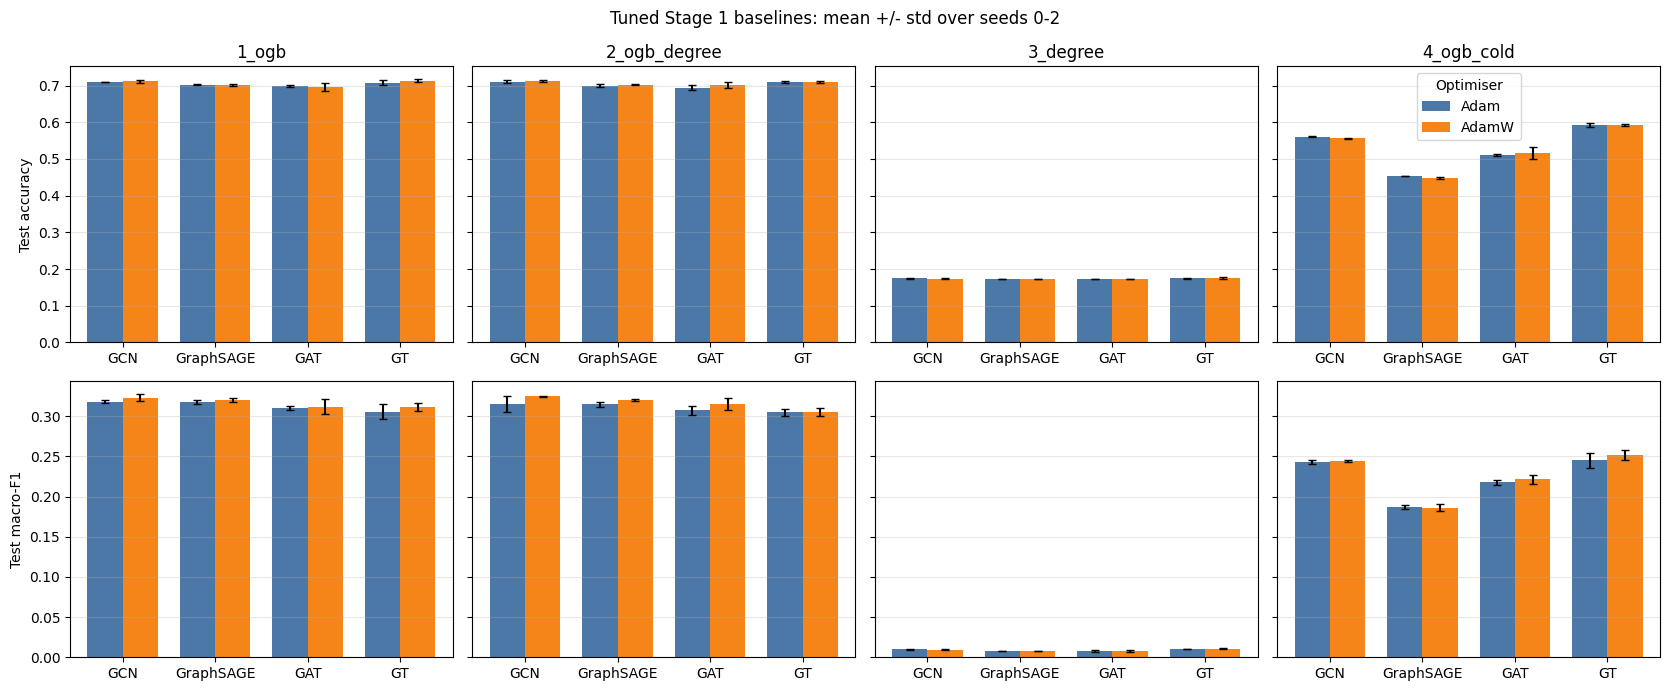

In [17]:
# Test accuracy and macro-F1 by model, optimiser and condition (mean +/- sample std over seeds).
test = all_metrics.query("split == 'test'")
stats = test.groupby(['condition', 'architecture', 'optimiser'])[['accuracy', 'macro_f1_present']].agg(['mean', 'std'])
conditions = CONDITIONS + [COLD_CONDITION]
fig, axes = plt.subplots(2, len(conditions), figsize=(4.2 * len(conditions), 7), sharey='row')
width = 0.38
for row, (metric, label) in enumerate([('accuracy', 'Test accuracy'), ('macro_f1_present', 'Test macro-F1')]):
    for col, condition in enumerate(conditions):
        ax = axes[row, col]
        for i, optimiser in enumerate(OPTIMISERS):
            means = [stats.loc[(condition, a, optimiser), (metric, 'mean')] for a in ARCHITECTURES]
            stds = [stats.loc[(condition, a, optimiser), (metric, 'std')] for a in ARCHITECTURES]
            ax.bar(np.arange(len(ARCHITECTURES)) + (i - 0.5) * width, means, width, yerr=stds, capsize=3,
                   label=optimiser, color=['#4C78A8', '#F58518'][i])
        ax.set_xticks(np.arange(len(ARCHITECTURES)), ARCHITECTURES)
        ax.set_title(condition if row == 0 else '')
        if col == 0:
            ax.set_ylabel(label)
        ax.grid(axis='y', alpha=0.3)
axes[0, -1].legend(title='Optimiser')
fig.suptitle('Tuned Stage 1 baselines: mean +/- std over seeds 0-2')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'test_accuracy_macro_f1.png', dpi=150, bbox_inches='tight')
plt.show()

In [18]:
# Total runtime per model (all sessions), also saved as runtime_per_model.csv.
display(write_runtime_files())

,cold_start_evaluation_runs,final_runs,grid_runs,cold_start_evaluation_seconds,final_seconds,grid_seconds,total_seconds,total_minutes
architecture,,,,,,,,
GCN,6,16,16,1.8,87.0,172.9,261.7,4.4
GraphSAGE,6,16,16,1.3,82.0,168.2,251.5,4.2
GAT,6,16,16,1.5,150.6,292.9,445.0,7.4
GT,6,16,16,2.5,1135.1,1205.2,2342.8,39.0
